# 01 · Exploring the human reviews

**Goal:** check that the cleaned human reviews (label 0) are suitable before any AI reviews are generated:

1. what the cleaning removed, and whether each rule removes what it should;
2. how the reviews are spread over time, games and recommendation (thumbs up/down);
3. how long they are;
4. known risks: reviews clustered at the end of collection windows, Steam Awards reviews;
5. how the second collection differs from the first one.

**Data:** `data/clean/v2/` from `scripts/collect_steam_reviews.py` (3,000 reviews per game, spread over 30-day windows, 2015 – 29 Nov 2022) and `scripts/clean_reviews.py`. The data folder is git-ignored: raw review text is not published. This notebook saves only **aggregated** tables and plots to `results/01_explore/`, and prints only a few short example reviews.

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebook lives in notebooks/, all paths are relative to the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw" / "v2"          # git-ignored, local only
CLEAN_DIR = ROOT / "data" / "clean" / "v2"      # git-ignored, local only
RESULTS_DIR = ROOT / "results" / "01_explore"   # aggregated tables and plots, safe to publish
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Optional: cleaned data of the FIRST collection (newest 3,000 per game), kept outside the repository.
# Change the path if yours is elsewhere; section 7 is skipped if the file does not exist.
OLD_CSV = ROOT.parent / "data_Steam" / "data" / "clean_data_Claude" / "reviews_clean.csv"

GAMES = {
    620: "Portal 2", 105600: "Terraria", 413150: "Stardew Valley", 292030: "Witcher 3",
    367520: "Hollow Knight", 646570: "Slay the Spire", 289070: "Civilization VI",
    1145360: "Hades", 1091500: "Cyberpunk 2077", 1517290: "Battlefield 2042",
    1151340: "Fallout 76", 578080: "PUBG",
}

# The same windows as in collect_steam_reviews.py (start date and length).
WINDOW_START = pd.Timestamp("2015-01-01", tz="UTC")
WINDOW_DAYS = 30

BLUE, INK2 = "#2a78d6", "#52514e"
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2})

In [2]:
df = pd.read_csv(CLEAN_DIR / "reviews_clean.csv")
report = json.loads((CLEAN_DIR / "cleaning_report.json").read_text(encoding="utf-8"))
dropped_examples = pd.read_csv(CLEAN_DIR / "dropped_examples.csv")

df["game"] = df["appid"].map(GAMES)
df["date"] = pd.to_datetime(df["timestamp_created"], unit="s", utc=True)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.strftime("%Y-%m")
dropped_examples["game"] = dropped_examples["appid"].map(GAMES)

# Games ordered by their first review in our data (roughly: when they came out on Steam).
GAME_ORDER = df.groupby("game")["date"].min().sort_values().index.tolist()

print(f"{len(df):,} kept reviews from {df['game'].nunique()} games, "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")

27,292 kept reviews from 12 games, 2015-01-28 to 2022-11-29


## 1. What the cleaning removed

Counts come from `cleaning_report.json`. Rules run in this order, and a review is counted only under the **first** rule that removes it.

In [3]:
RULES = ["dropped_empty", "dropped_repeated_characters", "dropped_mostly_symbols",
         "dropped_other_language_tag", "dropped_non_english_text", "dropped_too_short",
         "dropped_duplicate"]

overview = pd.DataFrame({"reviews": [report.get(rule, 0) for rule in RULES]}, index=RULES)
overview.loc["kept"] = report["kept"]
overview["share_of_collected_%"] = (100 * overview["reviews"] / report["input"]).round(1)
overview.to_csv(RESULTS_DIR / "cleaning_overview.csv")
overview

,reviews,share_of_collected_%
dropped_empty,111,0.3
dropped_repeated_characters,332,0.9
dropped_mostly_symbols,334,0.9
dropped_other_language_tag,0,0.0
dropped_non_english_text,189,0.5
dropped_too_short,6851,19.0
dropped_duplicate,891,2.5
kept,27292,75.8


Share of each game's collected reviews removed by each rule (in %). This answers why some games keep fewer reviews than others.

In [4]:
per_game = pd.DataFrame(report["dropped_per_app"]).fillna(0).astype(int)   # rows: appid, columns: rule
per_game.index = per_game.index.astype(int).map(GAMES)
per_game["kept"] = pd.Series({GAMES[int(a)]: n for a, n in report["kept_per_app"].items()})
collected = per_game.sum(axis=1)

per_game_share = (100 * per_game.div(collected, axis=0)).round(1).loc[GAME_ORDER]
per_game_share.to_csv(RESULTS_DIR / "cleaning_per_game_share.csv")
per_game_share

,dropped_duplicate,dropped_empty,dropped_mostly_symbols,dropped_non_english_text,dropped_repeated_characters,dropped_too_short,kept
Terraria,2.3,0.1,0.8,0.3,1.2,24.5,70.8
Portal 2,4.1,0.3,0.9,0.6,1.5,19.5,73.0
Witcher 3,4.6,0.3,0.6,0.7,0.7,17.9,75.2
Stardew Valley,2.7,0.2,0.7,0.2,0.7,17.2,78.3
Civilization VI,1.9,0.4,0.6,0.5,0.7,16.1,79.8
Hollow Knight,2.9,0.3,0.8,0.3,0.7,18.1,77.0
PUBG,2.8,0.2,2.0,2.0,1.3,29.3,62.3
Slay the Spire,2.7,0.2,1.0,0.4,0.5,18.1,77.0
Hades,1.5,0.5,1.0,0.3,0.9,19.4,76.4
Fallout 76,1.6,0.6,0.8,0.2,1.0,14.0,81.9


### 1.1 Does each rule remove what it should?

`dropped_examples.csv` holds 25 randomly picked removed reviews per rule. Below are the first 3 per rule, shortened. **Read all 25 per rule in the file itself** (open it in VS Code) and write what you found in the cell after the table: is there anything useful being removed, or noise that the rules miss?

In [5]:
def short(text, n=110):
    if pd.isna(text) or str(text).strip() == "":
        return "(empty)"
    text = str(text)
    return text if len(text) <= n else text[:n] + "…"

shown = dropped_examples.groupby("rule").head(3)
shown.assign(text=shown["text"].map(short))[["rule", "game", "text"]]

,rule,game,text
0,dropped_duplicate,PUBG,I LIKE THE GAME
1,dropped_duplicate,Hades,It's very good
2,dropped_duplicate,Terraria,This game is Amazing.
25,dropped_empty,Hades,(empty)
26,dropped_empty,PUBG,(empty)
27,dropped_empty,Stardew Valley,(empty)
50,dropped_mostly_symbols,Hollow Knight,.
51,dropped_mostly_symbols,Slay the Spire,.
52,dropped_mostly_symbols,Civilization VI,:)
75,dropped_non_english_text,Portal 2,Ｔｈｅ ｇａｍｅ＇ｓ ｇｏｔ ｌａｓｅｒｓ ａｎｄ ｌｅｍｏｎｓ ｗｈａｔ ｍｏｒｅ ｃｏｕ...


**Findings from reading `dropped_examples.csv`** *(fill in after reading; one line per rule, with a concrete example)*

- `dropped_too_short`: …
- `dropped_duplicate`: …
- `dropped_mostly_symbols`: …
- `dropped_repeated_characters`: …
- `dropped_non_english_text`: …
- `dropped_empty`: …

### 1.2 Duplicates: copies inside one game, or the same phrase across games?

The duplicate check runs across **all** games and keeps the first copy, in the order the files are read. So we re-run the cleaning code from `scripts/clean_reviews.py` (the same functions, not a copy) to get every removed duplicate, and look up which game holds the kept copy.

In [6]:
sys.path.insert(0, str(ROOT / "scripts"))
from clean_reviews import load_raw, clean, duplicate_key

raw = list(load_raw(RAW_DIR))
_, _, _, dropped_all = clean(raw, min_words=report["min_words"])

kept_copy_game = {duplicate_key(text): game for text, game in zip(df["text"], df["game"])}
dups = pd.DataFrame(dropped_all["dropped_duplicate"])
dups["game"] = dups["appid"].map(GAMES)
dups["kept_copy_game"] = dups["text"].map(lambda t: kept_copy_game.get(duplicate_key(t)))
dups["same_game"] = dups["game"] == dups["kept_copy_game"]

print(f"{len(dups):,} duplicates removed; "
      f"{dups['same_game'].mean():.0%} copy a review of the same game, "
      f"{1 - dups['same_game'].mean():.0%} copy a review of another game")
print("\nMost repeated texts (lowercased):")
print(dups["text"].str.lower().map(short).value_counts().head(10).to_string())

891 duplicates removed; 21% copy a review of the same game, 79% copy a review of another game

Most repeated texts (lowercased):
text
best game ever         44
very good game         31
i like it              23
i love this game       21
love this game         16
i like this game       11
it's a good game       11
best game ever made    11
its pretty good        10
best game ever.         9


**Interpretation** *(fill in)*: are the removed duplicates mostly copies inside one game (spam, copy-paste) or the same short phrase written for different games ("best game ever")? Removing identical texts across games is still useful for the model: the same text with the same label in both the training and the test set would make the test too easy. But it also removes some genuine reviews, which is worth one sentence in the report.

## 2. Spread over time

The collection asked for the same number of reviews from every 30-day window in which a game had reviews, so every game should be roughly flat over the years after it came out. Cleaning removes a different share in different periods, so the counts are not exactly equal.

In [7]:
by_year = pd.crosstab(df["game"], df["year"], margins=True, margins_name="Total").loc[GAME_ORDER + ["Total"]]
by_year.to_csv(RESULTS_DIR / "reviews_by_game_and_year.csv")
by_year

year,2015,2016,2017,2018,2019,2020,2021,2022,Total
game,,,,,,,,,
Terraria,307,287,305,288,275,248,206,207,2123
Portal 2,312,318,297,295,264,270,222,212,2190
Witcher 3,240,343,336,307,286,263,234,247,2256
Stardew Valley,0,335,391,360,347,333,304,279,2349
Civilization VI,0,116,433,418,406,364,331,325,2393
Hollow Knight,0,0,387,437,426,402,347,311,2310
PUBG,0,0,314,390,354,280,266,265,1869
Slay the Spire,0,0,53,523,480,458,389,408,2311
Hades,0,0,0,0,0,879,709,704,2292


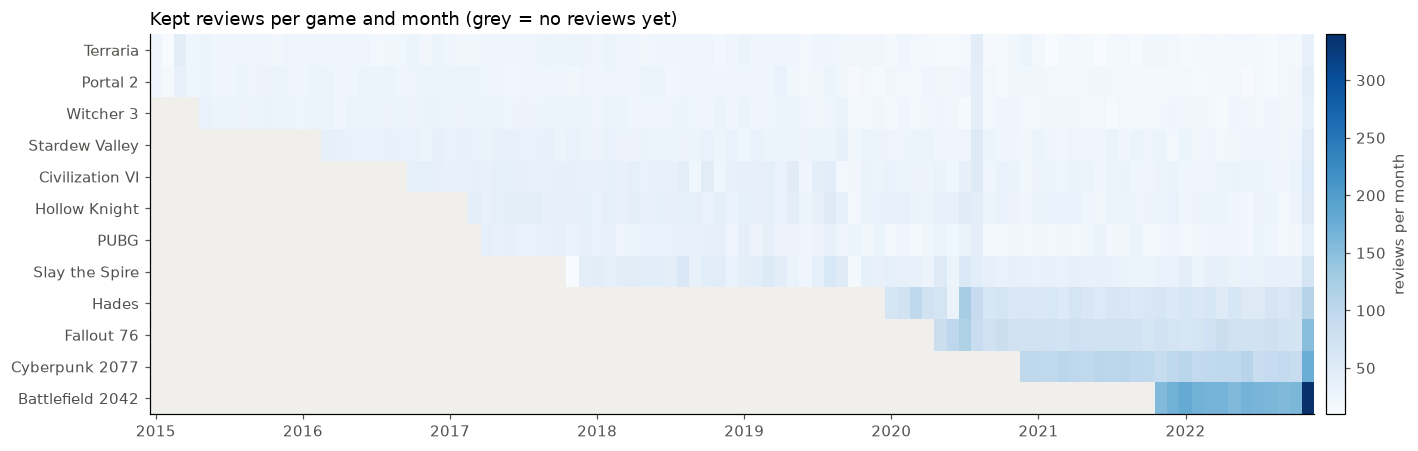

In [8]:
by_month = pd.crosstab(df["game"], df["month"]).reindex(GAME_ORDER)
by_month.to_csv(RESULTS_DIR / "reviews_by_game_and_month.csv")

fig, ax = plt.subplots(figsize=(13, 4.2))
data = np.ma.masked_equal(by_month.values, 0)
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f0efec")
im = ax.imshow(data, aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_yticks(range(len(GAME_ORDER)), GAME_ORDER)
january = [i for i, m in enumerate(by_month.columns) if m.endswith("-01")]
ax.set_xticks(january, [by_month.columns[i][:4] for i in january])
ax.set_title("Kept reviews per game and month (grey = no reviews yet)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="reviews per month")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "reviews_by_game_and_month.png", dpi=150)
plt.show()

### 2.1 Where inside a window do the reviews fall?

Inside each window the collector picks at random from the **newest ~100** reviews of that window. For popular games those can all be from the last day or two of the window. If reviews were spread evenly, each day of a 30-day window would hold about 3.3% of the reviews, and the last 3 days about 10%.

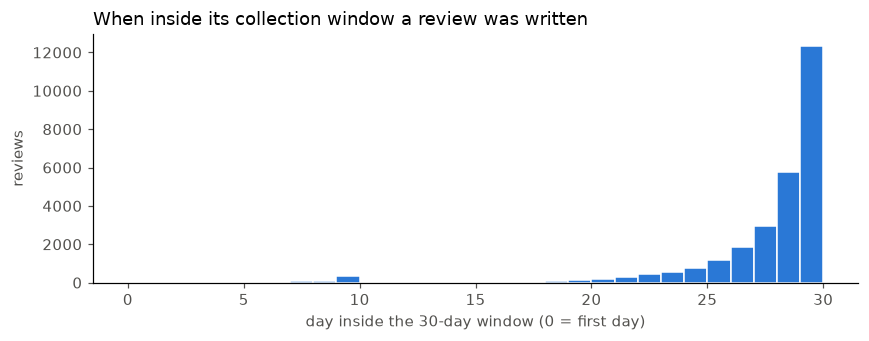

Reviews from the last 3 days of their window: 77% (about 10% if spread evenly)


,"last 3 days, %"
game,
Terraria,96.0
Portal 2,63.0
Witcher 3,87.0
Stardew Valley,83.0
Civilization VI,70.0
Hollow Knight,72.0
PUBG,98.0
Slay the Spire,61.0
Hades,88.0


In [9]:
df["day_in_window"] = ((df["date"] - WINDOW_START).dt.total_seconds() / 86400) % WINDOW_DAYS

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["day_in_window"], bins=WINDOW_DAYS, range=(0, WINDOW_DAYS), color=BLUE, edgecolor="white")
ax.set_xlabel("day inside the 30-day window (0 = first day)")
ax.set_ylabel("reviews")
ax.set_title("When inside its collection window a review was written", loc="left")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "day_in_window.png", dpi=150)
plt.show()

last3 = (df["day_in_window"] >= WINDOW_DAYS - 3).groupby(df["game"]).mean().mul(100).round(0)
print(f"Reviews from the last 3 days of their window: {(df['day_in_window'] >= WINDOW_DAYS - 3).mean():.0%} "
      "(about 10% if spread evenly)")
last3.loc[GAME_ORDER].rename("last 3 days, %").to_frame()

## 3. Recommendation (thumbs up / down)

AI reviews will be matched on recommendation, so both classes get the same share of positive reviews. What matters here is how many negative reviews there are and which games they come from.

In [10]:
sentiment = df.groupby("game").agg(reviews=("voted_up", "size"),
                                   positive_share=("voted_up", "mean"),
                                   negative=("voted_up", lambda s: int((~s.astype(bool)).sum())))
sentiment["positive_share"] = sentiment["positive_share"].round(3)
sentiment["share_of_all_negative_%"] = (100 * sentiment["negative"] / sentiment["negative"].sum()).round(1)
sentiment = sentiment.loc[GAME_ORDER]
sentiment.to_csv(RESULTS_DIR / "sentiment_by_game.csv")

print(f"Positive overall: {df['voted_up'].mean():.1%}, negative reviews: {int((~df['voted_up'].astype(bool)).sum()):,}")
sentiment

Positive overall: 84.1%, negative reviews: 4,343


,reviews,positive_share,negative,share_of_all_negative_%
game,,,,
Terraria,2123,0.975,54,1.2
Portal 2,2190,0.986,30,0.7
Witcher 3,2256,0.962,85,2.0
Stardew Valley,2349,0.984,37,0.9
Civilization VI,2393,0.712,689,15.9
Hollow Knight,2310,0.966,78,1.8
PUBG,1869,0.561,820,18.9
Slay the Spire,2311,0.972,64,1.5
Hades,2292,0.985,34,0.8


In [11]:
positive_by_year = df.pivot_table(index="game", columns="year", values="voted_up", aggfunc="mean").round(2).loc[GAME_ORDER]
positive_by_year.to_csv(RESULTS_DIR / "positive_share_by_game_and_year.csv")
positive_by_year

year,2015,2016,2017,2018,2019,2020,2021,2022
game,,,,,,,,
Terraria,0.97,0.99,0.98,0.96,0.97,0.99,0.99,0.95
Portal 2,0.99,0.98,0.99,0.98,0.98,1.00,1.00,0.98
Witcher 3,0.98,0.97,0.97,0.94,0.94,0.98,0.97,0.94
Stardew Valley,NaN,0.98,0.97,0.98,0.97,0.99,1.00,0.99
Civilization VI,NaN,0.58,0.56,0.57,0.71,0.86,0.87,0.82
Hollow Knight,NaN,NaN,0.96,0.96,0.97,0.97,0.98,0.96
PUBG,NaN,NaN,0.68,0.43,0.51,0.62,0.63,0.56
Slay the Spire,NaN,NaN,1.00,0.98,0.95,0.99,0.98,0.97
Hades,NaN,NaN,NaN,NaN,NaN,0.99,0.99,0.98


## 4. Length

Word counts use the same definition as the cleaning script (letters and apostrophes; numbers do not count). Reviews under 3 words were removed.

count    27292.0
mean        49.9
std        100.4
min          3.0
10%          4.0
25%          8.0
50%         19.0
75%         50.0
90%        115.9
99%        487.1
max       2220.0


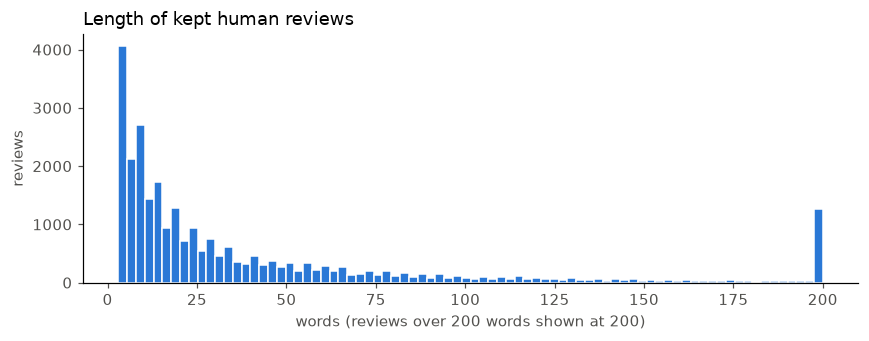

In [12]:
print(df["word_count"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["word_count"].clip(upper=200), bins=80, color=BLUE, edgecolor="white")
ax.set_xlabel("words (reviews over 200 words shown at 200)")
ax.set_ylabel("reviews")
ax.set_title("Length of kept human reviews", loc="left")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "length_histogram.png", dpi=150)
plt.show()

In [13]:
length = pd.DataFrame({
    "median_words": df.groupby("game")["word_count"].median(),
    "median_words_positive": df[df["voted_up"].astype(bool)].groupby("game")["word_count"].median(),
    "median_words_negative": df[~df["voted_up"].astype(bool)].groupby("game")["word_count"].median(),
}).loc[GAME_ORDER]
length.to_csv(RESULTS_DIR / "length_by_game.csv")

print("Median words by year:")
print(df.groupby("year")["word_count"].median().to_string())
length

Median words by year:
year
2015    18.0
2016    21.0
2017    28.0
2018    26.0
2019    20.0
2020    17.0
2021    16.0
2022    17.0


,median_words,median_words_positive,median_words_negative
game,,,
Terraria,14.0,14.0,14.5
Portal 2,15.0,14.0,32.0
Witcher 3,18.0,17.0,59.0
Stardew Valley,19.0,19.0,23.0
Civilization VI,24.0,19.0,47.0
Hollow Knight,24.0,23.0,59.0
PUBG,13.0,10.0,20.0
Slay the Spire,20.0,19.0,56.0
Hades,18.0,18.0,77.0


## 5. Steam Awards reviews

The first collection jumped on 22 Nov 2022, likely because of the Steam Autumn Sale and Steam Awards nominations ("It won labour of love for a reason"). These are real human reviews, so they stay in the data; we only check that they are not a large share.

In [14]:
AWARD = re.compile(r"steam award|labou?r of love|nominat", re.IGNORECASE)
df["mentions_award"] = df["text"].str.contains(AWARD)

print(f"Reviews mentioning the awards: {df['mentions_award'].sum():,} ({df['mentions_award'].mean():.2%})")
print("\nShare by calendar month (%), nominations run in late November:")
print((100 * df.groupby(df["date"].dt.month)["mentions_award"].mean()).round(2).to_string())

Reviews mentioning the awards: 49 (0.18%)

Share by calendar month (%), nominations run in late November:
date
1     0.19
2     0.15
3     0.09
4     0.09
5     0.30
6     0.14
7     0.25
8     0.24
9     0.14
10    0.14
11    0.27
12    0.10


## 6. First collection vs second collection

The first collection took the newest 3,000 reviews per game in one window. Skipped if `OLD_CSV` does not exist.

In [15]:
def describe(d):
    date = pd.to_datetime(d["timestamp_created"], unit="s", utc=True)
    last_window = date >= pd.Timestamp("2022-11-22", tz="UTC")
    return pd.Series({
        "kept reviews": len(d),
        "first review": f"{date.min():%Y-%m-%d}",
        "last review": f"{date.max():%Y-%m-%d}",
        "share from 22-29 Nov 2022": f"{last_window.mean():.1%}",
        "median words": d["word_count"].median(),
        "positive share": f"{d['voted_up'].mean():.1%}",
        "negative reviews": int((~d["voted_up"].astype(bool)).sum()),
    })

if OLD_CSV.exists():
    comparison = pd.DataFrame({"first collection": describe(pd.read_csv(OLD_CSV)),
                               "second collection (v2)": describe(df)})
    comparison.to_csv(RESULTS_DIR / "first_vs_second_collection.csv")
    display(comparison)
else:
    print(f"First collection not found at {OLD_CSV}, skipped.")

,first collection,second collection (v2)
kept reviews,24296,27292
first review,2022-07-08,2015-01-28
last review,2022-11-29,2022-11-29
share from 22-29 Nov 2022,39.7%,2.1%
median words,13.0,19.0
positive share,86.7%,84.1%
negative reviews,3220,4343


## 7. Summary

*(Fill in after running: 4–6 bullets with numbers, each one a claim we can use in the report. Then add any new failure or changed decision to `failure-journal.md`.)*

- Cleaning: …
- Time spread: …
- Clustering inside windows: …
- Recommendation: …
- Length: …
- Steam Awards: …